# Exercise 1: Explore the TAL1 locus

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BigMindLab/Tutorial_IA_ISCB-LATAM_2026/blob/dev/modules/M02_multiomics_alphagenome/notebooks/01_explore_locus_TAL1.ipynb)
**Time:** about 12 minutes, after environment setup and reference download.
**Reference genome:** GRCh38/hg38. **Annotation:** GENCODE v46, protein-coding MANE Select transcripts.

Run `00_setup.ipynb` first to check the environment and API access. This notebook
initializes its own imports and client because variables are not shared between notebooks.

By the end, you should be able to identify candidate regulatory regions, relate
predicted signals to transcription, and describe candidate chromatin domains.

| Activity | Suggested time |
| --- | ---: |
| Load the locus and predictions | 2 min |
| Compare expression and regulatory signals | 4 min |
| Inspect contact maps and discuss questions | 4 min |
| Try another context | 2 min |

### Which biological contexts are being compared?

The main comparison is **CD34-positive common myeloid progenitor vs liver**.
T cells can replace the progenitor context in the optional activity.
Neither the progenitor nor the T-cell context has a CTCF track or contact map in
the metadata checked during preparation. Liver has CTCF but no contact map.
An unavailable track is **missing coverage**, not evidence of an absent biological signal.

We therefore show contact maps separately for **GM12878** (a lymphoblastoid cell
line) and **HepG2** (a liver-derived cancer cell line). These are different samples
from the main comparison. Their maps cannot establish boundaries in CD34-positive
progenitors, primary liver, T cells, or T-ALL cells.

All displayed assay signals are **model predictions**, not measurements from the
participants' samples. This exercise uses the reference sequence; it does not
introduce the TAL1 MuTE insertion or predict its effect (Exercise 2).

## 1. Locate the workshop and import the client

In Codespaces, select the workshop Python kernel. In Colab, use a CPU runtime;
the cell below installs the same AlphaGenome version as the setup notebook.
The API key is read by the shared helper. Do not paste it into this notebook.

In [3]:
import importlib.util
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/BigMindLab/Tutorial_IA_ISCB-LATAM_2026"
REPO_REF = "dev"

MODULE_RELATIVE_PATH = Path("modules/M02_multiomics_alphagenome")

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Find the module from the current directory or its parents.
MODULE_DIR = None

for parent in (Path.cwd(), *Path.cwd().parents):
    for candidate in (parent, parent / MODULE_RELATIVE_PATH):
        if (candidate / "utils" / "ag_helpers.py").is_file():
            MODULE_DIR = candidate.resolve()
            break
    if MODULE_DIR is not None:
        break

# Colab may have opened only the notebook, without the repository files.
if MODULE_DIR is None:
    if not IN_COLAB:
        raise FileNotFoundError(
            "Workshop files not found. Open this notebook inside "
            "the workshop repository."
        )

    checkout = Path("/content/alphagenome-workshop")

    if not checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "--branch", REPO_REF,
                REPO_URL, str(checkout),
            ],
            check=True,
        )

    MODULE_DIR = (checkout / MODULE_RELATIVE_PATH).resolve()

if not (MODULE_DIR / "utils" / "ag_helpers.py").is_file():
    raise FileNotFoundError(
        "ag_helpers.py was not found in the selected repository checkout. "
        "Check REPO_REF and the repository structure."
    )

print("Environment:", "Google Colab" if IN_COLAB else "Local / Codespaces")
print("Module directory:", MODULE_DIR)

if IN_COLAB:
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "--quiet",
            "alphagenome==0.10.0", "pyarrow",  # same pin as requirements.txt
        ],
        check=True,
    )
    print("Colab dependencies installed.")
else:
    missing = [
        name
        for name in ("alphagenome", "pyarrow")
        if importlib.util.find_spec(name) is None
    ]

    if missing:
        raise RuntimeError(
            "Missing packages: "
            + ", ".join(missing)
            + ". Select the workshop Python kernel. "
            "If the problem persists, check the Codespaces environment."
        )

    print("Using the existing workshop environment.")

Environment: Local / Codespaces
Module directory: /workspaces/Tutorial_IA_ISCB-LATAM_2026/modules/M02_multiomics_alphagenome
Using the existing workshop environment.


In [4]:
import hashlib
import json
import time
from functools import lru_cache
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from alphagenome.data import gene_annotation, genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components

utils_dir = str(MODULE_DIR / "utils")
if utils_dir not in sys.path:
    sys.path.insert(0, utils_dir)
import ag_helpers

model = ag_helpers.get_client(prompt=False)
print("AlphaGenome:", version("alphagenome"))
print("Shared helper:", ag_helpers.__file__)
print("Client configured:", model is not None)
print("A configured client is verified when a request succeeds.")

@lru_cache(maxsize=1)
def reference_gtf(url):
    """Reuse the downloaded reference in this kernel when changing genes."""
    return pd.read_feather(url)

/home/vscode/.local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Live mode: requests go to the AlphaGenome API (the key is checked on the first one).
AlphaGenome: 0.10.0
Shared helper: /workspaces/Tutorial_IA_ISCB-LATAM_2026/modules/M02_multiomics_alphagenome/utils/ag_helpers.py
Client configured: True
A configured client is verified when a request succeeds.


## 2. Choose the gene and contexts

Keep these defaults for the guided exercise. Ontology IDs select the biosample
tracks that AlphaGenome supports; they do not create a new experimental sample.
The output metadata will identify the exact tracks returned.

For the optional activity, change `GENE_SYMBOL` or replace `BLOOD_CONTEXT` with
`"CL:0000084"` (T cell), then rerun from this cell onward. New combinations require
live access unless their own precomputed results have been generated.

In [5]:
GENE_SYMBOL = "TAL1"
BLOOD_CONTEXT = "CL:0001059"       # Common myeloid progenitor, CD34-positive.
COMPARISON_CONTEXT = "UBERON:0002107"  # Liver.
CONTACT_CONTEXTS = ["EFO:0002784", "EFO:0001187"]  # GM12878 and HepG2.

# Maintainers: enable only when intentionally generating real offline copies.
SAVE_PRECOMPUTED = False

ANNOTATION_URL = (
    "https://storage.googleapis.com/alphagenome/reference/gencode/"
    "hg38/gencode.v46.annotation.gtf.gz.feather"
)
HISTONE_MARKS = ["H3K27ac", "H3K4me3"]
MAIN_CONTEXTS = [BLOOD_CONTEXT, COMPARISON_CONTEXT]
if len(set(MAIN_CONTEXTS)) != 2:
    raise ValueError("Choose two distinct main contexts.")

def result_name(label, request):
    """Give each request its own deterministic precomputed-result name."""
    encoded = json.dumps(request, sort_keys=True).encode()
    digest = hashlib.sha256(encoded).hexdigest()[:16]
    return f"ex1_{label}_{digest}"

def interval_spec(value):
    """Use JSON-compatible coordinates for provenance and serialization."""
    return {
        "chromosome": str(value.chromosome),
        "start": int(value.start),
        "end": int(value.end),
        "strand": str(value.strand),
        "name": value.name,
    }

exercise_start = time.perf_counter()

## 3. Load the annotated locus and expand to 1 Mb

`interval.resize(2**20)` requests **1,048,576 bp** centered on the gene.
GENCODE determines the coordinates and strand; no gene coordinates are hard-coded.

The first live run downloads the reference annotation. Only complete MANE Select
transcripts overlapping this locus (plus a small plotting margin) are retained in
the exercise bundle. This download can take additional time.

Every bundle is obtained through `ag_helpers.cached_call`. Without a client,
the corresponding real precomputed bundle must already exist. Result names below
define new exercise outputs; they do not imply those files have been supplied.

In [6]:
annotation_request = {
    "schema": 1,
    "assembly": "hg38",
    "annotation_url": ANNOTATION_URL,
    "gene_symbol": GENE_SYMBOL.strip().upper(),
    "window_bp": 2**20,
    "transcripts": "protein-coding MANE Select",
    "plot_margin_bp": 4096,
}
annotation_name = result_name("annotation", annotation_request)

def prepare_annotation():
    gtf = reference_gtf(ANNOTATION_URL)
    gene_interval = gene_annotation.get_gene_interval(
        gtf, gene_symbol=annotation_request["gene_symbol"]
    )
    interval = gene_interval.resize(2**20)
    if interval.start < 0:
        raise ValueError("The centered window extends beyond the chromosome start.")

    mane = gene_annotation.filter_to_mane_select_transcript(
        gene_annotation.filter_protein_coding(gtf)
    )
    overlapping = (
        mane["Feature"].eq("transcript")
        & mane["Chromosome"].eq(interval.chromosome)
        & (mane["Start"] < interval.end + 4096)
        & (mane["End"] > interval.start - 4096)
    )
    ids = mane.loc[overlapping, "transcript_id"].dropna().unique()
    # Retain full transcripts and exons, rather than truncating rows at the window.
    local_gtf = mane.loc[mane["transcript_id"].isin(ids)].copy()
    if not local_gtf["gene_name"].str.upper().eq(
        annotation_request["gene_symbol"]
    ).any():
        raise ValueError("The selected gene has no protein-coding MANE Select transcript.")

    return {
        "request": annotation_request,
        "gene_interval": interval_spec(gene_interval),
        "gtf": local_gtf,
    }

annotation_bundle = ag_helpers.cached_call(
    annotation_name, prepare_annotation, save=SAVE_PRECOMPUTED
)
if annotation_bundle["request"] != annotation_request:
    raise ValueError("The annotation bundle does not match this request.")

gene_interval = genome.Interval(**annotation_bundle["gene_interval"])
interval = gene_interval.resize(2**20)
local_gtf = annotation_bundle["gtf"]
transcript_extractor = transcript_utils.TranscriptExtractor(local_gtf)

print("Gene:", gene_interval)
print("Prediction interval:", interval)
print("Window width:", interval.width, "bp")
print("Annotation result name:", annotation_name)
display(
    local_gtf.loc[local_gtf["Feature"].eq("transcript"),
                  ["gene_name", "transcript_id", "Strand", "Start", "End"]]
    .reset_index(drop=True)
)

Gene: chr1:47216289-47232225:-
Prediction interval: chr1:46699969-47748545:-
Window width: 1048576 bp
Annotation result name: ex1_annotation_e206745dfd25bfab


,gene_name,transcript_id,Strand,Start,End
0,EFCAB14,ENST00000371933.8,-,46675158,46719114
1,CYP4B1,ENST00000371923.9,+,46799045,46819413
2,CYP4A11,ENST00000310638.9,-,46929187,46941476
3,CYP4X1,ENST00000371901.4,+,47023668,47050751
4,CYP4Z1,ENST00000334194.4,+,47067230,47118318
5,CYP4A22,ENST00000371891.8,+,47137440,47149727
6,PDZK1IP1,ENST00000294338.7,-,47183581,47190036
7,TAL1,ENST00000691006.1,-,47216290,47232225
8,STIL,ENST00000371877.8,-,47250138,47314147
9,CMPK1,ENST00000371873.10,+,47333789,47378839


## 4. Predict expression, accessibility, histone marks and CTCF

One `predict_interval` request covers both main contexts. We request RNA-seq,
DNase, histone ChIP-seq and TF ChIP-seq, then retain H3K27ac, H3K4me3 and CTCF
from the ChIP outputs. Filtering before saving keeps offline bundles smaller.

With a client, `cached_call` runs the live request. A gRPC failure falls back to
the matching precomputed result if one exists. Without a client it loads that
result directly. It does not automatically save live results in this notebook
unless `SAVE_PRECOMPUTED` is enabled.

In [7]:
main_request = {
    "schema": 1,
    "assembly": "hg38",
    "interval": interval_spec(interval),
    "ontology_terms": MAIN_CONTEXTS,
    "requested_outputs": ["RNA_SEQ", "DNASE", "CHIP_HISTONE", "CHIP_TF"],
    "retained_histone_marks": HISTONE_MARKS,
    "retained_tf": "CTCF",
}
main_name = result_name("multimodal", main_request)

def predict_main():
    output = model.predict_interval(
        interval=interval,
        organism=dna_client.Organism.HOMO_SAPIENS,
        requested_outputs=[
            dna_client.OutputType.RNA_SEQ,
            dna_client.OutputType.DNASE,
            dna_client.OutputType.CHIP_HISTONE,
            dna_client.OutputType.CHIP_TF,
        ],
        ontology_terms=MAIN_CONTEXTS,
    )
    histones = output.chip_histone
    if histones is not None:
        histones = histones.filter_tracks(
            histones.metadata["histone_mark"].isin(HISTONE_MARKS).to_numpy()
        )
    ctcf = output.chip_tf
    if ctcf is not None:
        ctcf = ctcf.filter_tracks(
            ctcf.metadata["transcription_factor"].eq("CTCF").to_numpy()
        )
    return {
        "request": main_request,
        "tracks": {
            "RNA_SEQ": output.rna_seq,
            "DNASE": output.dnase,
            "CHIP_HISTONE": histones,
            "CTCF": ctcf,
        },
    }

main_bundle = ag_helpers.cached_call(
    main_name, predict_main, save=SAVE_PRECOMPUTED
)
if main_bundle["request"] != main_request:
    raise ValueError("The prediction bundle does not match this request.")
tracks = main_bundle["tracks"]
print("Multimodal result name:", main_name)

Multimodal result name: ex1_multimodal_9f595dd96c6ff6c2


### Check the actual output before interpretation

The table lists the tracks that were returned. All RNA-seq assays and strands are
retained: a single biosample term can have more than one track. Compare predicted
patterns while considering assay type, strand, and normalization; these values
are not gene-level TPM measurements.

Missing CTCF coverage is reported explicitly. It must never be drawn as a flat
zero-valued track.

In [8]:
def select_tracks(tdata, ontology_term=None, marker_column=None, marker=None):
    """Select tracks by their real metadata, preserving the TrackData object."""
    if tdata is None:
        return None
    mask = np.ones(len(tdata.metadata), dtype=bool)
    if ontology_term is not None:
        mask &= tdata.metadata["ontology_curie"].eq(ontology_term).to_numpy()
    if marker_column is not None:
        mask &= tdata.metadata[marker_column].eq(marker).to_numpy()
    return tdata.filter_tracks(mask)

def require_tracks(tdata, label, ndim):
    if tdata is None or tdata.values.shape[-1] == 0:
        raise ValueError(f"No supported tracks returned for {label}.")
    if tdata.values.ndim != ndim or tdata.interval is None:
        raise ValueError(f"Unexpected shape or missing interval for {label}.")
    if not np.isfinite(tdata.values).all():
        raise ValueError(f"Non-finite prediction values in {label}.")
    expected_bins = tdata.interval.width // tdata.resolution
    if tdata.interval.width % tdata.resolution or any(
        size != expected_bins for size in tdata.values.shape[:-1]
    ):
        raise ValueError(f"Array dimensions do not match the interval for {label}.")

metadata_tables = []
for label, tdata in tracks.items():
    if tdata is not None and tdata.values.shape[-1]:
        require_tracks(tdata, label, ndim=2)
        metadata_tables.append(tdata.metadata.assign(output_type=label))

returned_metadata = pd.concat(metadata_tables, ignore_index=True)
columns = [
    "output_type", "biosample_name", "ontology_curie", "name", "strand",
    "Assay title", "histone_mark", "transcription_factor",
]
display(returned_metadata[[c for c in columns if c in returned_metadata.columns]])

for context in MAIN_CONTEXTS:
    for label in ["RNA_SEQ", "DNASE"]:
        require_tracks(select_tracks(tracks[label], context), f"{label}: {context}", 2)
    for mark in HISTONE_MARKS:
        require_tracks(
            select_tracks(tracks["CHIP_HISTONE"], context, "histone_mark", mark),
            f"{mark}: {context}", 2,
        )
    ctcf_context = select_tracks(tracks["CTCF"], context)
    count = 0 if ctcf_context is None else ctcf_context.values.shape[-1]
    print(f"CTCF coverage for {context}: {count} track(s)")

require_tracks(tracks["CTCF"], "CTCF in at least one main context", 2)
print("Required main outputs: validated.")

,output_type,biosample_name,ontology_curie,name,strand,Assay title,histone_mark,transcription_factor
0,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 polyA plus RNA-seq,+,polyA plus RNA-seq,NaN,NaN
1,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 total RNA-seq,+,total RNA-seq,NaN,NaN
2,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 polyA plus RNA-seq,-,polyA plus RNA-seq,NaN,NaN
3,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 total RNA-seq,-,total RNA-seq,NaN,NaN
4,RNA_SEQ,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 polyA plus RNA-seq,.,polyA plus RNA-seq,NaN,NaN
5,RNA_SEQ,liver,UBERON:0002107,UBERON:0002107 polyA plus RNA-seq,.,polyA plus RNA-seq,NaN,NaN
6,DNASE,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 DNase-seq,.,DNase-seq,NaN,NaN
7,DNASE,liver,UBERON:0002107,UBERON:0002107 DNase-seq,.,DNase-seq,NaN,NaN
8,CHIP_HISTONE,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 Histone ChIP-seq H3K27ac,.,Histone ChIP-seq,H3K27ac,NaN
9,CHIP_HISTONE,"common myeloid progenitor, CD34-positive",CL:0001059,CL:0001059 Histone ChIP-seq H3K4me3,.,Histone ChIP-seq,H3K4me3,NaN


CTCF coverage for CL:0001059: 0 track(s)
CTCF coverage for UBERON:0002107: 1 track(s)
Required main outputs: validated.


## 5. Read the 1 Mb overview

Look for accessible regions, promoter-associated H3K4me3 and active
regulatory-region-associated H3K27ac. Histone marks and accessibility nominate
**candidate** regulatory regions; these predictions do not establish enhancer
function or an enhancer's target gene.

Each modality/mark uses a shared y-axis scale across its displayed tracks. Scales
and units differ between modalities. RNA-seq and DNase are sum-pooled into 128 bp
bins for these plots only; the saved arrays retain their native resolution.

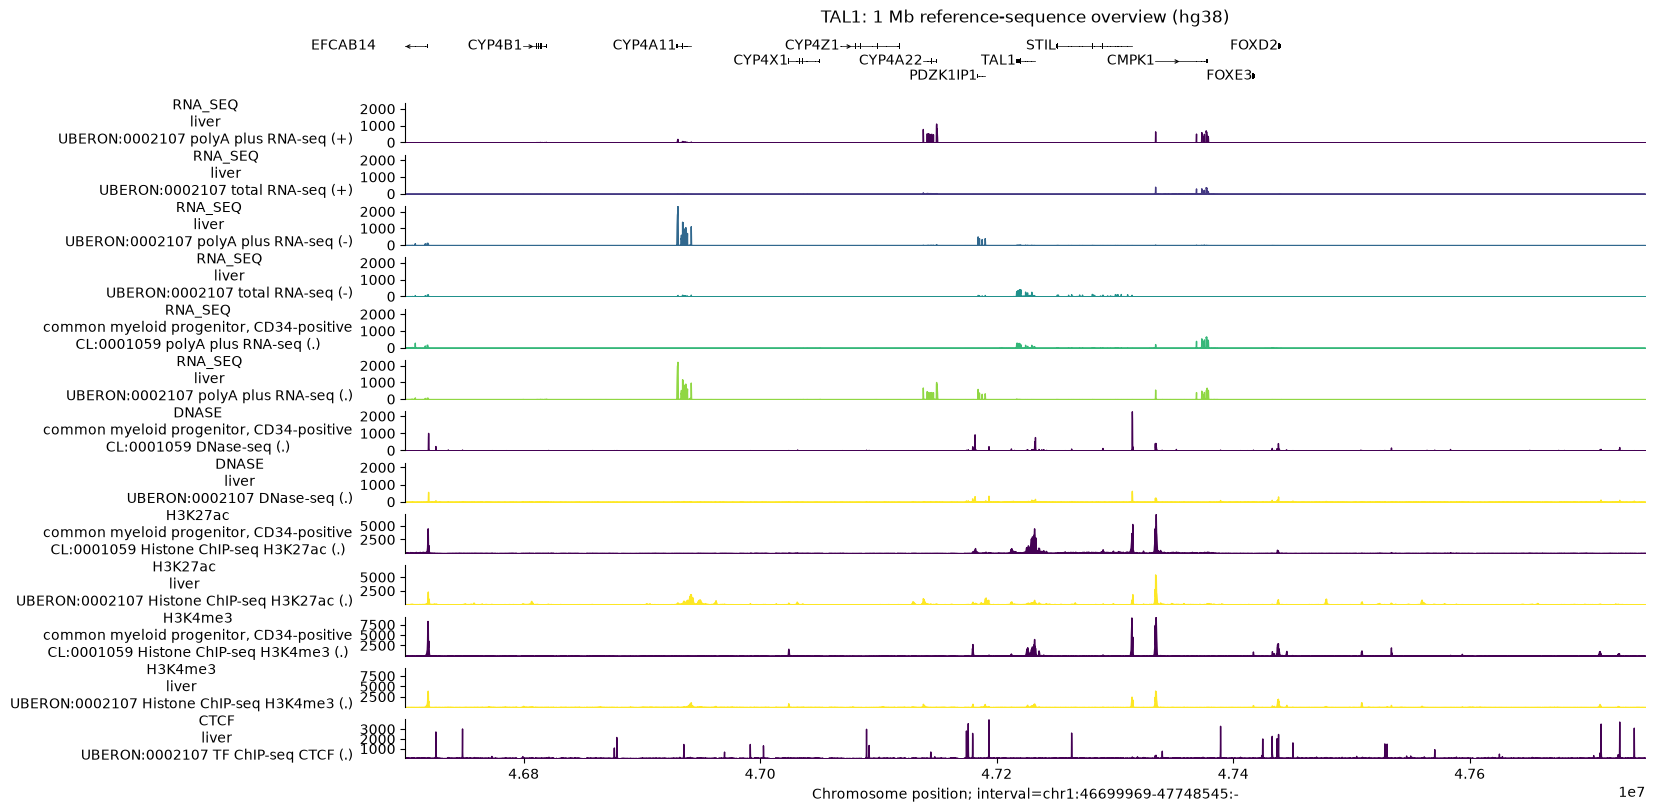

In [9]:
def plot_locus(view_interval, title):
    components = [
        plot_components.TranscriptAnnotation(
            transcript_extractor.extract(view_interval)
        )
    ]
    panels = [
        ("RNA_SEQ", tracks["RNA_SEQ"]),
        ("DNASE", tracks["DNASE"]),
        *[
            (mark, select_tracks(tracks["CHIP_HISTONE"],
                                 marker_column="histone_mark", marker=mark))
            for mark in HISTONE_MARKS
        ],
        ("CTCF", tracks["CTCF"]),
    ]
    for label, tdata in panels:
        if tdata is None or not tdata.values.shape[-1]:
            continue
        # Use all returned tracks rather than choosing an arbitrary first assay.
        plotted = tdata.change_resolution(128) if tdata.resolution == 1 else tdata
        components.append(
            plot_components.Tracks(
                plotted,
                ylabel_template=label + "\n{biosample_name}\n{name} ({strand})",
                shared_y_scale=True,
                filled=True,
                track_height=0.65,
            )
        )
    fig = plot_components.plot(
        components,
        interval=view_interval,
        title=title,
        fig_width=16,
    )
    plt.show()
    return fig

overview_figure = plot_locus(
    interval, f"{GENE_SYMBOL}: 1 Mb reference-sequence overview (hg38)"
)

### Zoom in without making another API request

Inspect transcription direction, exons and nearby regulatory signals at higher
visual resolution. For TAL1, the negative strand means that upstream is toward
higher genomic coordinates (the right side of these plots). Do not assume that
every gene you try has the same orientation.

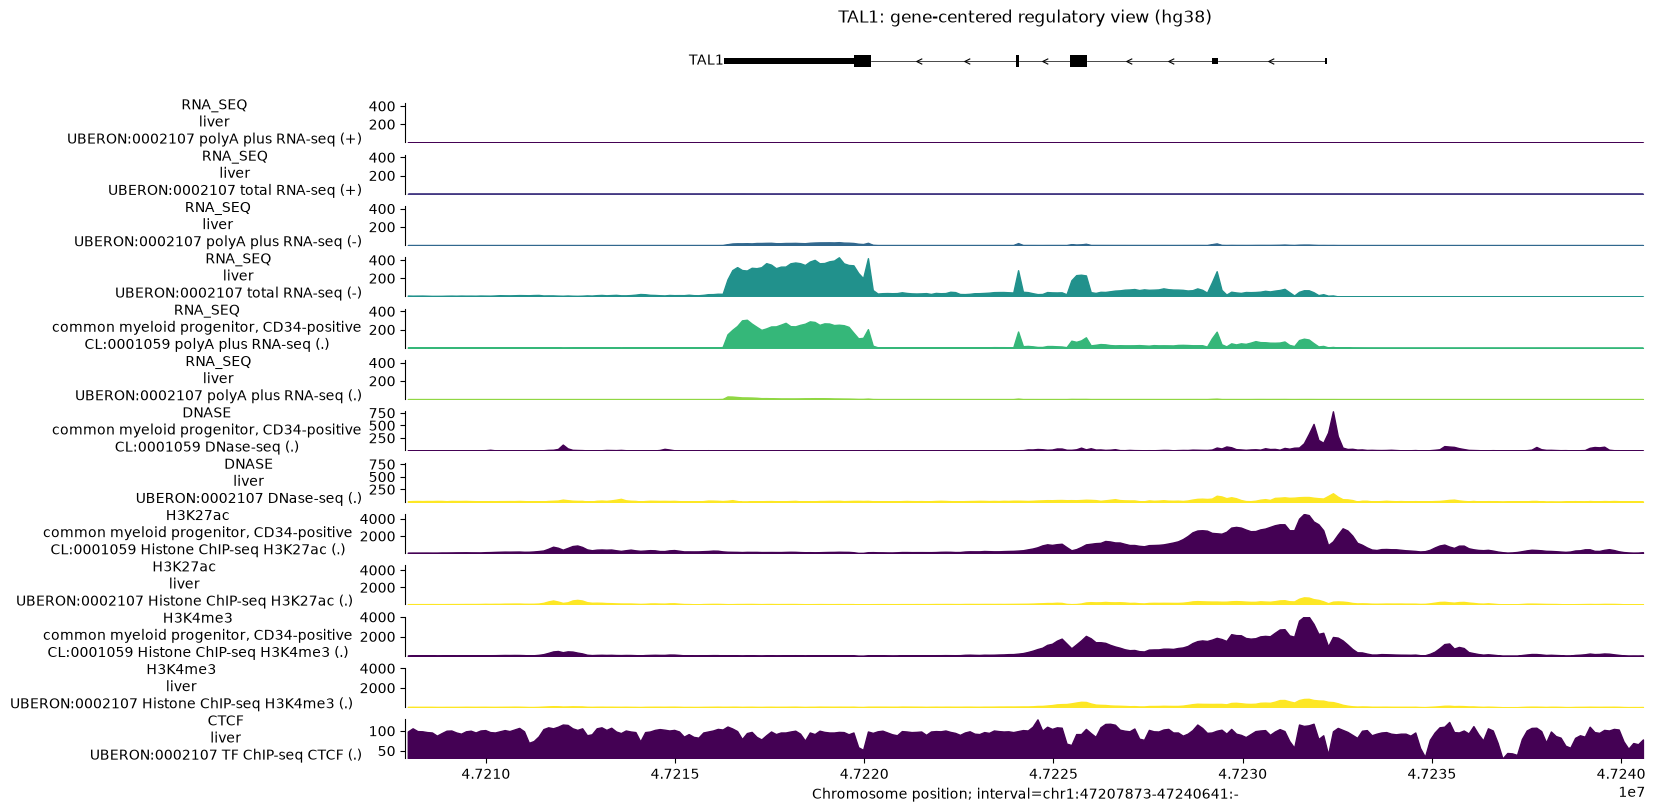

In [10]:
# Keep the plotting interval inside the prediction and its width divisible by 128.
zoom_width = min(2**20, max(2**15, ((gene_interval.width + 16383) // 128) * 128))
zoom_interval = gene_interval.resize(zoom_width)
zoom_figure = plot_locus(
    zoom_interval, f"{GENE_SYMBOL}: gene-centered regulatory view (hg38)"
)

## 6. Explore contact maps in the available cell lines

This second prediction uses the **same 1 Mb input window**, with contact maps for
GM12878 and HepG2. Both maps use the same color scale. The values describe
log-fold contact signal over an expectation based on genomic distance, rather
than raw contact counts or probabilities.

Look for regions of stronger internal contact separated by weaker contact across
their edges. These can suggest **candidate domain boundaries**. We are inspecting
the model's maps visually, not running a TAD-calling algorithm. CTCF from primary
liver in the preceding plot is not a matched measurement for either cell line.

Contact result name: ex1_contacts_212bed4ac9f09ab1
Returned contact interval: chr1:46699969-47748545:.
Contact resolution: 2048 bp
Contact array shape: (512, 512, 2)


,biosample_name,ontology_curie,name
0,GM12878,EFO:0002784,4dn:4DNFIXP4QG5B
1,HepG2,EFO:0001187,4dn:4DNFIS6HAUPP


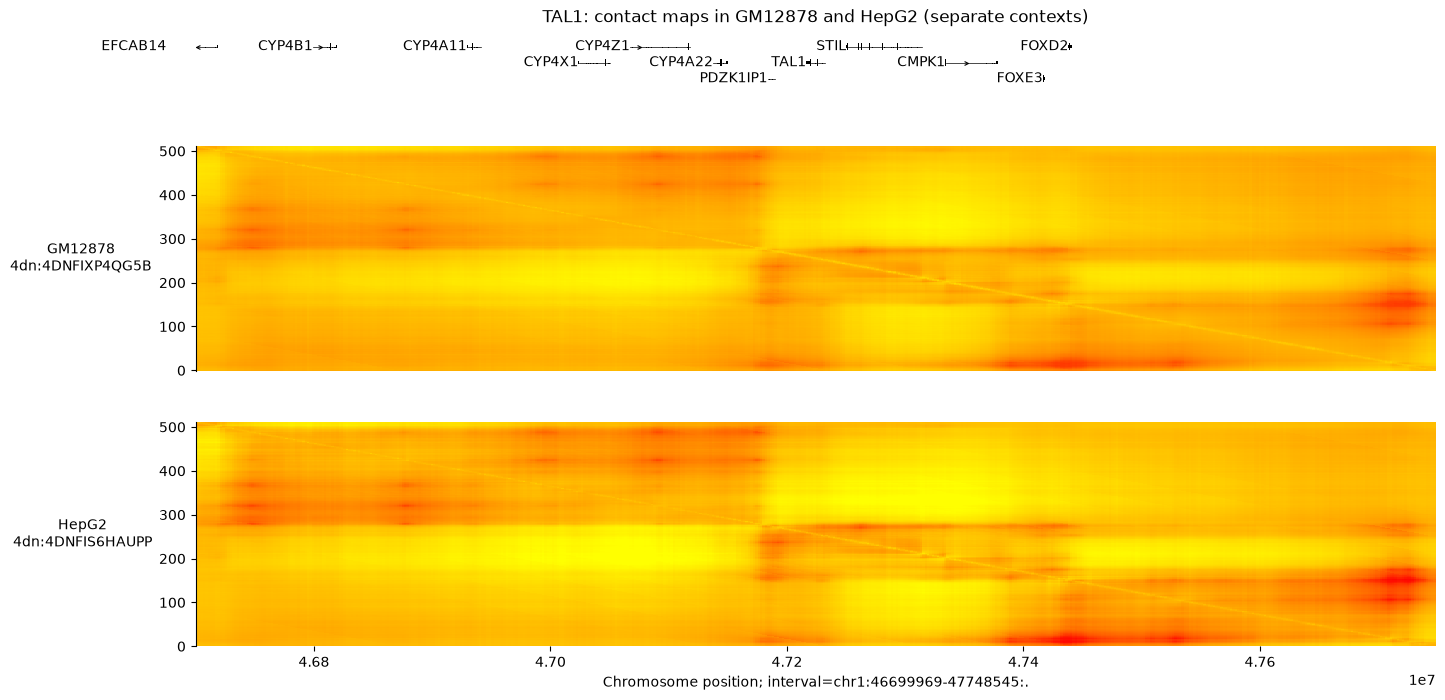

Elapsed time so far: 17.6 seconds


In [11]:
contact_request = {
    "schema": 1,
    "assembly": "hg38",
    "interval": interval_spec(interval),
    "ontology_terms": CONTACT_CONTEXTS,
    "requested_outputs": ["CONTACT_MAPS"],
}
contact_name = result_name("contacts", contact_request)

def predict_contacts():
    output = model.predict_interval(
        interval=interval,
        organism=dna_client.Organism.HOMO_SAPIENS,
        requested_outputs=[dna_client.OutputType.CONTACT_MAPS],
        ontology_terms=CONTACT_CONTEXTS,
    )
    return {"request": contact_request, "tracks": output.contact_maps}

contact_bundle = ag_helpers.cached_call(
    contact_name, predict_contacts, save=SAVE_PRECOMPUTED
)
if contact_bundle["request"] != contact_request:
    raise ValueError("The contact-map bundle does not match this request.")
contacts = contact_bundle["tracks"]
require_tracks(contacts, "CONTACT_MAPS", ndim=3)
for context in CONTACT_CONTEXTS:
    require_tracks(select_tracks(contacts, context), f"CONTACT_MAPS: {context}", 3)

print("Contact result name:", contact_name)
print("Returned contact interval:", contacts.interval)
print("Contact resolution:", contacts.resolution, "bp")
print("Contact array shape:", contacts.values.shape)
display(contacts.metadata[["biosample_name", "ontology_curie", "name"]])

# Plot using the actual returned interval, including any SDK coordinate alignment.
contact_figure = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(
            transcript_extractor.extract(contacts.interval)
        ),
        plot_components.ContactMaps(
            contacts,
            ylabel_template="{biosample_name}\n{name}",
            vmin=-1.0,
            vmax=2.0,
            track_height=3.5,
        ),
    ],
    interval=contacts.interval,
    title=f"{GENE_SYMBOL}: contact maps in GM12878 and HepG2 (separate contexts)",
    fig_width=16,
)
plt.show()

print(f"Elapsed time so far: {time.perf_counter() - exercise_start:.1f} seconds")

## 7. Guided questions

1. **Promoter:** Using transcript direction, H3K4me3 and DNase, where would you
   nominate a promoter for TAL1? Give an approximate coordinate and explain how
   you distinguished the transcription start from the transcription end.
2. **Candidate enhancers:** Where do you see accessible regions with H3K27ac away
   from the annotated start site? Which differ between progenitor and liver?
   What evidence would be needed to assign one of these regions to TAL1?
3. **Expression:** Do the predicted RNA-seq tracks show signal over TAL1 exons in
   either context? Describe the assay and strand before comparing patterns.
   Why would this reference-sequence comparison not establish MuTE-induced TAL1
   activation in T-ALL?
4. **Chromatin domains:** Nominate one possible domain boundary in each contact
   map and describe the visual evidence. Are the patterns similar? Explain why
   the liver CTCF track cannot validate a boundary in GM12878, and why neither
   map determines the domain structure in CD34-positive progenitors.

Write observations from your actual figures. There are no assumed expression
levels, enhancer coordinates or domain boundaries in the exercise code.

## 8. Try it yourself

Choose one short activity:

- **Change the lineage context:** set `BLOOD_CONTEXT = "CL:0000084"` (T cell) in
  Section 2 and rerun from that section. Describe one change in predicted signal.
- **Change the gene:** set `GENE_SYMBOL = "HBB"` and rerun from Section 2.
  Compare the gene's orientation and regulatory signals with TAL1.

Changing parameters gives a different result name. Without live access, a new
combination needs its own precomputed bundle; it must not silently reuse the
default TAL1 predictions. Without that bundle, use the default figures to
complete the guided questions instead.

The first live run for a new gene may need to download reference annotation.
The reference DataFrame is reused within the same kernel.

## References

[AlphaGenome quick start](https://www.alphagenomedocs.com/colabs/v1/quick_start.html),
[TAL1 analysis workflow](https://www.alphagenomedocs.com/colabs/v1/example_analysis_workflow.html),
[model output metadata](https://www.alphagenomedocs.com/exploring_model_metadata.html),
and the module README for the biological case study.